# Data Analysis

This notebook analyzes the filtered sample of early-career data and analytics job postings. It summarizes detected skill mentions, fields of study listed in postings, experience statements, and regional role composition.

## Workflow
- Load the full featured dataset for context and the formal analysis sample for findings
- Measure skill mentions by role family
- Compare common skill combinations and fields of study listed in postings
- Summarize the main findings and limitations


In [2]:
import sys
sys.path.append("..")
import pandas as pd
from IPython.display import display
from config.settings import PROJECT_ROOT, MAJOR_GROUPS
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter
sns.set_theme(style = 'whitegrid', palette = 'deep')
from itertools import combinations

### Data preparation

The full featured dataset provides classification context. Analysis metrics use the pipeline-filtered `analysis_jobs.jsonl` sample.


In [3]:
# Read file, show the distributions, and set output directory.
featured_df = pd.read_json(PROJECT_ROOT / 'data' / 'processed' / 'featured_jobs.jsonl', orient='records', lines=True, encoding='utf-8')
analysis_df = pd.read_json(PROJECT_ROOT / 'data' / 'processed' / 'analysis_jobs.jsonl', orient='records', lines=True, encoding='utf-8')
role_family_counts = featured_df['classified_role_family'].value_counts().rename_axis('classified_role_family').reset_index(name='count')
display(role_family_counts)

career_level_counts = featured_df['classified_career_level'].value_counts().rename_axis('classified_career_level').reset_index(name='count')
display(career_level_counts)

job_province_counts = featured_df['job_province_clean'].value_counts().rename_axis('job_province').reset_index(name='count')
display(job_province_counts)

job_city_counts = featured_df['job_city_clean'].value_counts().rename_axis('job_city').reset_index(name='count')
display(job_city_counts)

output_directory = PROJECT_ROOT / 'outputs' / 'figures'

,classified_role_family,count
0,business_analyst,98
1,data_scientist,96
2,data_analyst,87
3,other,76
4,data_engineer,72
5,bi_analyst,30
6,outside_scope,25
7,hybrid,7
8,adjacent_hybrid,1


,classified_career_level,count
0,internship,205
1,unknown,161
2,potential_senior,59
3,entry_level,46
4,new_grad,21


,job_province,count
0,QC,185
1,ON,129
2,CALIFORNIA,18
3,SK,11
4,BC,7
5,AB,2


,job_city,count
0,Montreal,161
1,Toronto,84
2,Markham,10
3,Cañada,7
4,Mississauga,5
5,Québec City,4
6,Ottawa,3
7,Meadow Lake,3
8,Surrey,3
9,Montreal-Ouest,2


## 1. Overall technical and soft skill mentions

This section measures the share of postings in the formal analysis sample where each configured skill keyword was detected. Detection does not distinguish required, preferred, or incidental mentions.


In [4]:
# Explore which technical skill and soft skill are the most demanded.
total_jobs = analysis_df['job_id'].nunique()
# Establish a long table of technical skills
technical_skills_long = analysis_df[['job_id', 'classified_role_family', 'classified_career_level', 'technical_skills']].explode('technical_skills').dropna(subset=['technical_skills']).drop_duplicates(subset=['job_id', 'technical_skills']).reset_index(drop=True)
display(technical_skills_long)
# Calculate the proportion of technical skills for all positions.
technical_skills_demand = technical_skills_long['technical_skills'].value_counts().rename_axis('technical_skill').reset_index(name='count')
technical_skills_demand['proportion'] = technical_skills_demand['count'] / total_jobs
display(technical_skills_demand)

# Establish a long table of soft skills
soft_skills_long = analysis_df[['job_id', 'classified_role_family', 'classified_career_level', 'soft_skills']].explode('soft_skills').dropna(subset=['soft_skills']).drop_duplicates(subset=['job_id', 'soft_skills']).reset_index(drop=True)
display(soft_skills_long)
# Calculate the proportion of soft skills for all positions.
soft_skills_demand = soft_skills_long['soft_skills'].value_counts().rename_axis('soft_skill').reset_index(name='count')
soft_skills_demand['proportion'] = soft_skills_demand['count'] / total_jobs
display(soft_skills_demand)

,job_id,classified_role_family,classified_career_level,technical_skills
0,YmluZzotMTExOTIwMDAzOC5SZXRybw,data_analyst,internship,python
1,YmluZzotMTExOTIwMDAzOC5SZXRybw,data_analyst,internship,sql
2,YmluZzotMTExOTIwMDAzOC5SZXRybw,data_analyst,internship,tableau
3,YmluZzotMTExOTIwMDAzOC5SZXRybw,data_analyst,internship,power_bi
4,YmluZzoxOTQxNTk1ODc1LlJldHJv,data_analyst,internship,python
...,...,...,...,...
431,WV9uaVlUVmRyVjVGT1Z6S0FBQUFBQT09OkVzd0JDb3dCUV...,data_engineer,internship,aws
432,WV9uaVlUVmRyVjVGT1Z6S0FBQUFBQT09OkVzd0JDb3dCUV...,data_engineer,internship,azure
433,WV9uaVlUVmRyVjVGT1Z6S0FBQUFBQT09OkVzd0JDb3dCUV...,data_engineer,internship,gcp
434,aDQzUGgwNzd1VlRxZFhib0FBQUFBQT09OkVzd0JDb3dCUV...,data_engineer,internship,aws


,technical_skill,count,proportion
0,python,84,0.466667
1,sql,70,0.388889
2,excel,53,0.294444
3,power_bi,36,0.200000
4,aws,36,0.200000
5,tableau,29,0.161111
6,azure,26,0.144444
7,git,18,0.100000
8,gcp,15,0.083333
9,scikit_learn,12,0.066667


,job_id,classified_role_family,classified_career_level,soft_skills
0,YmluZzotMTExOTIwMDAzOC5SZXRybw,data_analyst,internship,communication
1,YmluZzoxNTIwMTY3ODguUmV0cm8,data_scientist,internship,communication
2,YmluZzoxNTIwMTY3ODguUmV0cm8,data_scientist,internship,teamwork
3,YmluZzoxNTIwMTY3ODguUmV0cm8,data_scientist,internship,problem_solving
4,YmluZzoxNTIwMTY3ODguUmV0cm8,data_scientist,internship,stakeholder_management
...,...,...,...,...
325,Q1ZFRlJHOHloQVlnaWdvT0FBQUFBQT09OkVzd0JDb3dCUV...,data_scientist,internship,attention_to_detail
326,NEZyTXBkVENRdGVxYWNKM0FBQUFBQT09OkVzd0JDb3dCUV...,data_engineer,internship,teamwork
327,bzZJZXFDYjVXU2JNb1p4eUFBQUFBQT09OkVzd0JDb3dCUV...,data_engineer,internship,teamwork
328,bzZJZXFDYjVXU2JNb1p4eUFBQUFBQT09OkVzd0JDb3dCUV...,data_engineer,internship,problem_solving


,soft_skill,count,proportion
0,teamwork,112,0.622222
1,communication,72,0.400000
2,problem_solving,71,0.394444
3,attention_to_detail,35,0.194444
4,time_management,28,0.155556
5,stakeholder_management,8,0.044444
6,presentation,4,0.022222


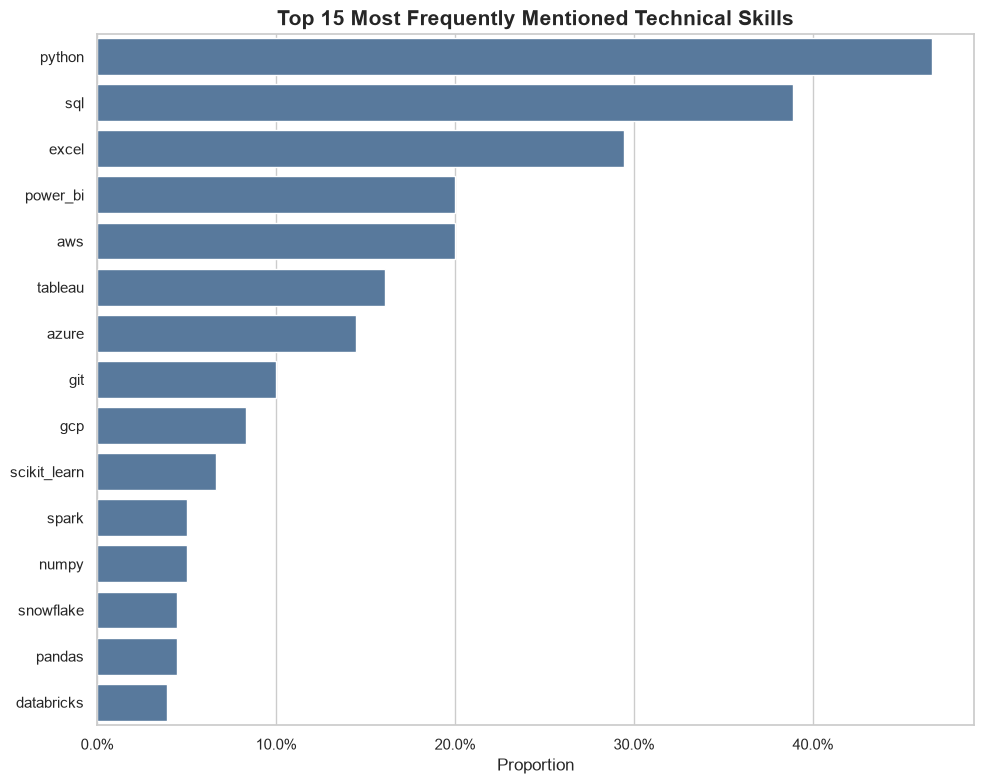

In [5]:
# Draw the top 15 technical skills horizontal bar chart
technical_top_15 = technical_skills_demand.nlargest(15, 'proportion').sort_values('proportion', ascending=False)
fig, ax = plt.subplots(figsize=(10, 8))
sns.barplot(data=technical_top_15,
            y='technical_skill',
            x='proportion',
            color='#4C78A8',
            ax=ax,
            )
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlabel('Proportion')
ax.set_ylabel('')
ax.set_title('Top 15 Most Frequently Mentioned Technical Skills',
             fontsize=15,
             fontweight='bold',)
plt.tight_layout()
fig.savefig(
    output_directory / 'top_15_most_frequently_mentioned_technical_skills_Sept.png',
    dpi=200,
    bbox_inches='tight',
)
plt.show()

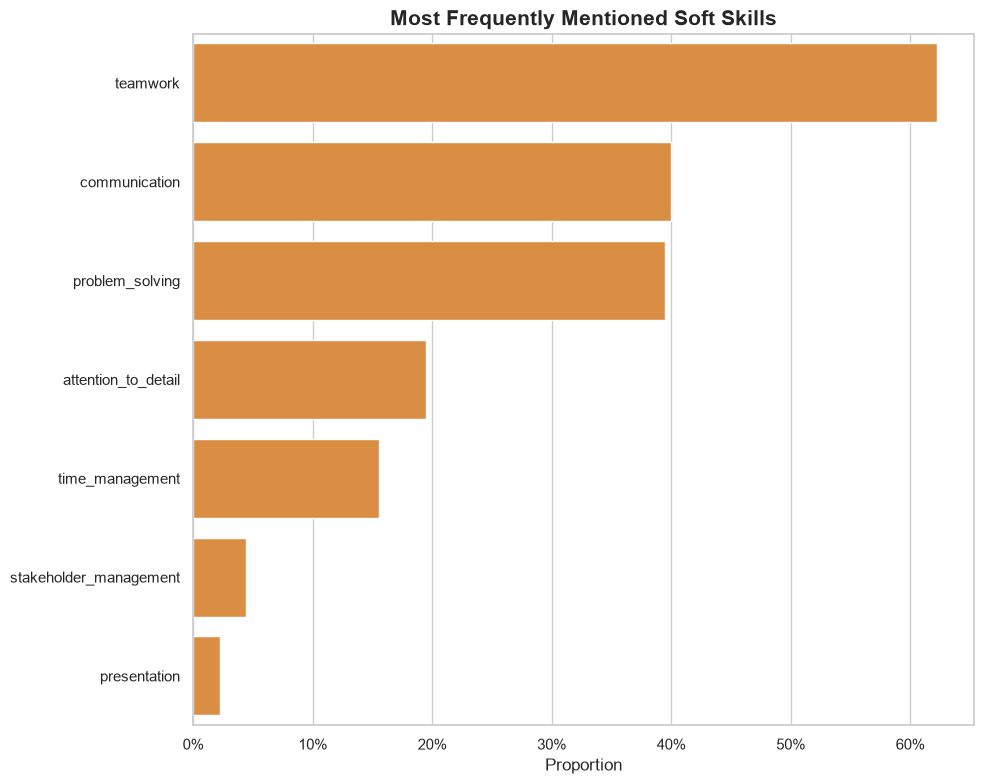

In [6]:
# Draw the soft skills horizontal bar chart
soft_skills = soft_skills_demand.sort_values('proportion', ascending=False)
fig, ax = plt.subplots(figsize=(10, 8))
sns.barplot(data=soft_skills,
            y='soft_skill',
            x='proportion',
            color='#F28E2B',
            ax=ax,
            )
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlabel('Proportion')
ax.set_ylabel('')
ax.set_title('Most Frequently Mentioned Soft Skills',
             fontsize=15,
             fontweight='bold',
             )
plt.tight_layout()
fig.savefig(
    output_directory / 'most_frequently_mentioned_soft_skills_Sept.png',
    dpi=200,
    bbox_inches='tight',
)
plt.show()

### Findings

- Python and SQL are the most frequently mentioned technical skills.
- SQL appears across both analytics-oriented and engineering-oriented roles, suggesting strong cross-functional value.
- Percentages use the formal analysis sample as their denominator.


## 2. Technical skills by role family

This section compares detected skill mentions across the role families. Proportions are calculated within each role-family sample.


In [7]:
# Explore the differences in the skill requirements for different positions
role_job_counts = analysis_df.groupby('classified_role_family')['job_id'].nunique().rename('total_jobs').reset_index()
technical_skills_each_role = technical_skills_long.groupby(['classified_role_family', 'technical_skills'])['job_id'].nunique().rename('skill_job_count').reset_index()
technical_skills_each_role = technical_skills_each_role.merge(role_job_counts, on='classified_role_family', how='left')
technical_skills_each_role['proportion'] = technical_skills_each_role['skill_job_count'] / technical_skills_each_role['total_jobs']
display(technical_skills_each_role)

top_skills = technical_skills_demand.nlargest(10, 'proportion')['technical_skill']
skill_role_matrix = technical_skills_each_role[technical_skills_each_role['technical_skills'].isin(top_skills)].pivot(index='technical_skills', columns='classified_role_family', values='proportion').fillna(0).reindex(top_skills)
display(skill_role_matrix)

,classified_role_family,technical_skills,skill_job_count,total_jobs,proportion
0,bi_analyst,azure,2,8,0.250000
1,bi_analyst,databricks,2,8,0.250000
2,bi_analyst,excel,4,8,0.500000
3,bi_analyst,git,1,8,0.125000
4,bi_analyst,power_bi,2,8,0.250000
5,bi_analyst,python,3,8,0.375000
6,bi_analyst,spark,2,8,0.250000
7,bi_analyst,sql,6,8,0.750000
8,bi_analyst,tableau,4,8,0.500000
9,business_analyst,azure,4,44,0.090909


classified_role_family,bi_analyst,business_analyst,data_analyst,data_engineer,data_scientist
technical_skill,,,,,
python,0.375,0.227273,0.426230,0.628571,0.71875
sql,0.750,0.250000,0.459016,0.285714,0.46875
excel,0.500,0.454545,0.377049,0.000000,0.18750
power_bi,0.250,0.204545,0.245902,0.028571,0.28125
aws,0.000,0.000000,0.114754,0.685714,0.15625
tableau,0.500,0.113636,0.229508,0.000000,0.18750
azure,0.250,0.090909,0.065574,0.314286,0.15625
git,0.125,0.000000,0.049180,0.400000,0.00000
gcp,0.000,0.000000,0.000000,0.371429,0.06250


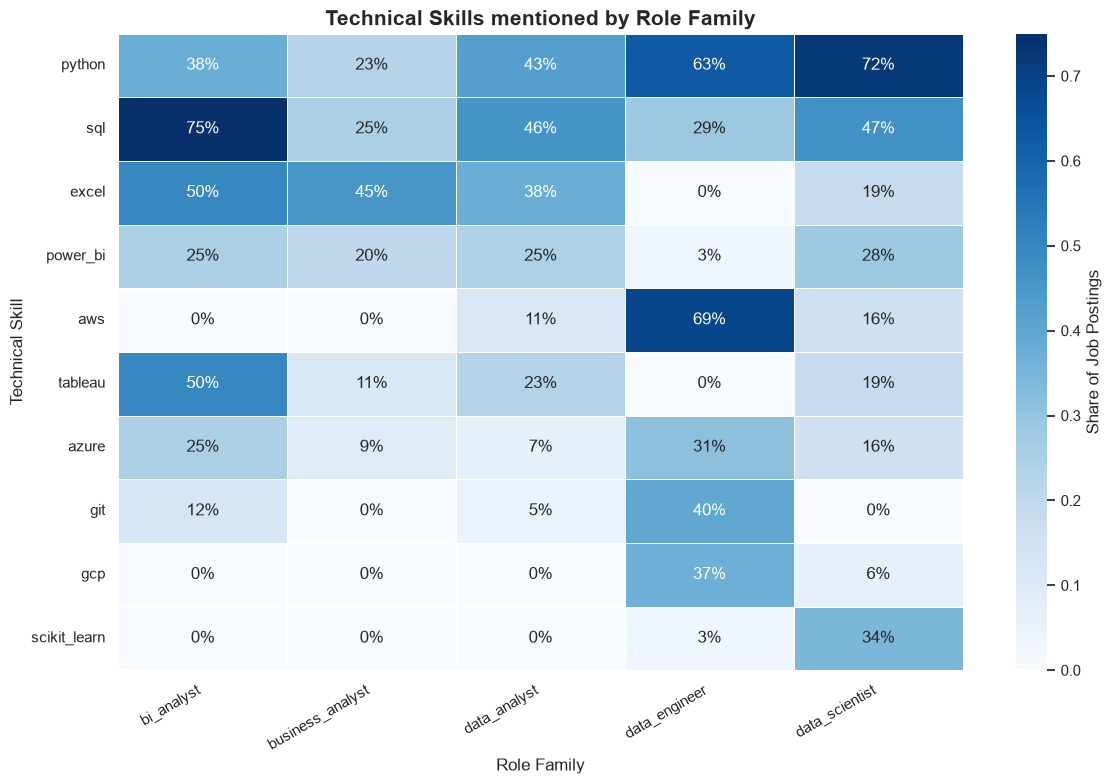

In [8]:
# Draw the heatmap of the top 10 technical skills by role family
fig, ax = plt.subplots(figsize=(12, 8))
sns.heatmap(skill_role_matrix,
            annot=True,
            fmt='.0%',
            cmap='Blues',
            linewidths=0.5,
            cbar_kws={'label': 'Share of Job Postings'},
            )
plt.title('Technical Skills mentioned by Role Family', fontsize=15, fontweight='bold')
plt.xlabel('Role Family')
plt.ylabel('Technical Skill')
plt.xticks(rotation=30, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
fig.savefig(
    output_directory / 'technical_skills_mentioned_by_role_family_Sept.png',
    dpi=200,
    bbox_inches='tight',
)
plt.show()

### Sample sizes by role family

- BI analyst: 8
- Business analyst: 44
- Data analyst: 61
- Data scientist: 32
- Data engineer: 35

These counts are useful for directional comparison, but percentages for smaller groups should be interpreted more cautiously.


### Findings

- SQL was particularly common among BI Analyst postings.
- Python was more prominent in Data Scientist and Data Engineer positions.
- Cloud platforms were more concentrated in Data Engineer postings.

## 3. Technical skill combinations

Single-skill demand is useful, but many roles require multiple capabilities together. Here we inspect the most common pairs and triples of technical skills to capture real-world combinations employers frequently request.


In [9]:
# Explore the technical_skill combinations
skill_pairs = []
for skill in analysis_df['technical_skills']:
    if not isinstance(skill, list):
        continue
    unique_skills = sorted(set(skill))
    skill_pairs.extend(combinations(unique_skills, 2))
# Statistics of the most common skills
skill_pair_counts = pd.Series(skill_pairs).value_counts().rename_axis('skill_pair').reset_index(name='count')
total_jobs = analysis_df['job_id'].nunique()
skill_pair_counts['proportion'] = skill_pair_counts['count'] / total_jobs
display(skill_pair_counts)

,skill_pair,count,proportion
0,"(python, sql)",54,0.300000
1,"(power_bi, sql)",33,0.183333
2,"(excel, sql)",32,0.177778
3,"(excel, python)",29,0.161111
4,"(aws, python)",27,0.150000
...,...,...,...
105,"(databricks, excel)",1,0.005556
106,"(excel, spark)",1,0.005556
107,"(git, tableau)",1,0.005556
108,"(aws, power_bi)",1,0.005556


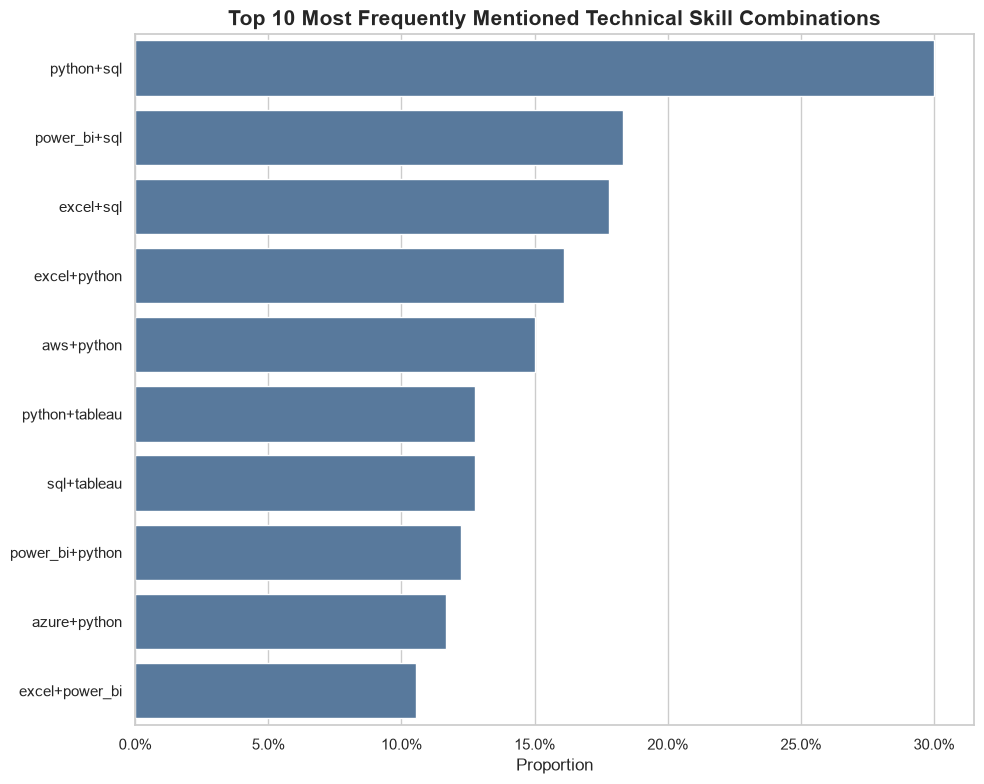

In [10]:
# Draw the top 10 technical skill combinations horizontal bar chart
skill_pair_counts['pair_label'] = skill_pair_counts['skill_pair'].map(lambda x: '+'.join(x))
top_10_pairs = skill_pair_counts.nlargest(10, 'proportion').sort_values('proportion', ascending=False)
fig, ax = plt.subplots(figsize=(10, 8))
sns.barplot(data=top_10_pairs,
            y='pair_label',
            x='proportion',
            color='#4C78A8',
            ax=ax,
            )
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlabel('Proportion')
ax.set_ylabel('')
ax.set_title('Top 10 Most Frequently Mentioned Technical Skill Combinations',
             fontsize=15,
             fontweight='bold',)
plt.tight_layout()
fig.savefig(
    output_directory / 'top_10_most_frequently_mentioned_technical_skill_combinations_Sept.png',
    dpi=200,
    bbox_inches='tight',
)
plt.show()

In [11]:
# Analysis of the combination of three technical skills
skill_triples = []
for skills in analysis_df['technical_skills']:
    if not isinstance(skills, list):
        continue
    unique_skills = sorted(set(skills))
    skill_triples.extend(combinations(unique_skills, 3))
skill_triple_counts = (pd.Series(skill_triples).value_counts().rename_axis('skill_triple').reset_index(name='count'))
skill_triple_counts['proportion'] = (skill_triple_counts['count'] / analysis_df['job_id'].nunique())

top_triples = skill_triple_counts.nlargest(10, 'proportion').sort_values('proportion', ascending=False).copy()
top_triples['skill_bundle'] = top_triples['skill_triple'].map(lambda x: ' + '.join(x))
display(top_triples[['skill_bundle', 'count', 'proportion']])

,skill_bundle,count,proportion
0,power_bi + python + sql,21,0.116667
1,python + sql + tableau,18,0.100000
2,excel + power_bi + sql,18,0.100000
3,excel + python + sql,18,0.100000
4,power_bi + sql + tableau,16,0.088889
5,aws + python + sql,15,0.083333
6,aws + gcp + python,14,0.077778
7,power_bi + python + tableau,12,0.066667
8,aws + azure + python,12,0.066667
9,python + scikit_learn + sql,12,0.066667


### Findings
- Python and SQL formed the most common technical skill pair, appearing together in 30% of the collected postings.
- The results suggest two broad skill profiles: a BI-oriented stack centred on SQL, Excel and Power BI, and a programming-oriented stack centred on Python, SQL and cloud or machine-learning tools.
- Power BI, Python and SQL was the most common three-skill bundle, but it appeared in only 11.7% of postings, indicating that technical requirements remain diverse across roles.
- These findings suggest that Python and SQL provide the broadest foundation, while visualization, cloud and machine-learning tools should be selected according to the target role family.

## 4. Fields of study listed in postings

This section examines fields detected in education-related text. Detection does not establish whether an employer accepts or excludes a particular field of study.


In [12]:
# Explore the distribution for major required by employers
total_job_with_major = analysis_df['accepted_majors'].apply(lambda x: isinstance(x, list) and len(x) > 0).sum()
# Establish a long table of accepted_majors
accepted_majors_long = analysis_df[['job_id', 'classified_role_family', 'classified_career_level', 'accepted_majors']].explode('accepted_majors').dropna(subset=['accepted_majors']).drop_duplicates(subset=['job_id', 'accepted_majors']).reset_index(drop=True)
display(accepted_majors_long)
# Calculate the proportion of accepted majors for all positions.
accepted_majors_demand = accepted_majors_long['accepted_majors'].value_counts().rename_axis('accepted_major').reset_index(name='count')
accepted_majors_demand['proportion'] = accepted_majors_demand['count'] / total_job_with_major
display(accepted_majors_demand)
major_coverage = total_job_with_major / analysis_df["job_id"].nunique()
print(f'Major requirement coverage: {major_coverage:.1%}')

,job_id,classified_role_family,classified_career_level,accepted_majors
0,YmluZzotMTExOTIwMDAzOC5SZXRybw,data_analyst,internship,engineering
1,YmluZzotMTExOTIwMDAzOC5SZXRybw,data_analyst,internship,economics
2,YmluZzotMTYxMDc0NDE0MC5SZXRybw,data_analyst,new_grad,computer_science
3,YmluZzotMTYxMDc0NDE0MC5SZXRybw,data_analyst,new_grad,statistics
4,YmluZzotMTYxMDc0NDE0MC5SZXRybw,data_analyst,new_grad,mathematics
...,...,...,...,...
253,bzZJZXFDYjVXU2JNb1p4eUFBQUFBQT09OkVzd0JDb3dCUV...,data_engineer,internship,data_science
254,bzZJZXFDYjVXU2JNb1p4eUFBQUFBQT09OkVzd0JDb3dCUV...,data_engineer,internship,engineering
255,aDQzUGgwNzd1VlRxZFhib0FBQUFBQT09OkVzd0JDb3dCUV...,data_engineer,internship,computer_science
256,aDQzUGgwNzd1VlRxZFhib0FBQUFBQT09OkVzd0JDb3dCUV...,data_engineer,internship,statistics


,accepted_major,count,proportion
0,computer_science,56,0.577320
1,engineering,43,0.443299
2,data_science,43,0.443299
3,business,39,0.402062
4,statistics,30,0.309278
5,mathematics,26,0.268041
6,finance,11,0.113402
7,economics,5,0.051546
8,management,5,0.051546


Major requirement coverage: 53.9%


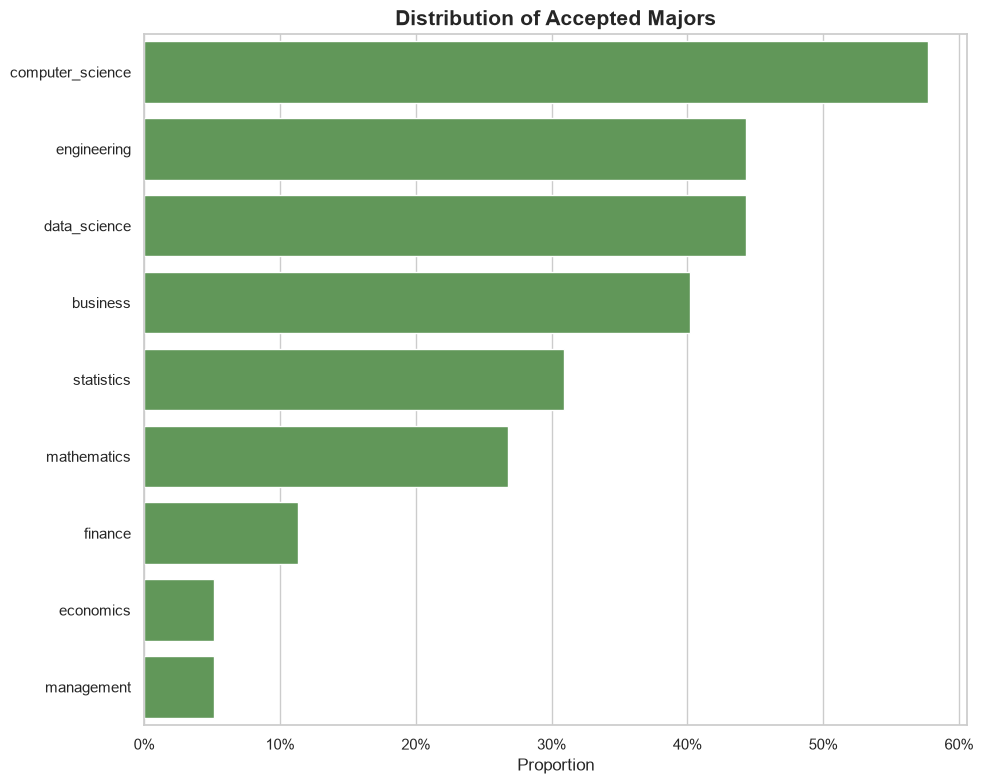

In [13]:
# Draw the accepted majors horizontal bar chart
major_plot = accepted_majors_demand.sort_values('proportion', ascending=False)
fig, ax = plt.subplots(figsize=(10, 8))
sns.barplot(data=major_plot,
            y='accepted_major',
            x='proportion',
            color='#59A14F',
            ax=ax,
            )
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlabel('Proportion')
ax.set_ylabel('')
ax.set_title('Distribution of Accepted Majors',
             fontsize=15,
             fontweight='bold',
             )
plt.tight_layout()
fig.savefig(
    output_directory / 'distribution_of_accepted_majors_Sept.png',
    dpi=200,
    bbox_inches='tight',
)
plt.show()

In [14]:
# Comparative overview for different major groups
def classify_major_groups(majors):
    if not isinstance(majors, list):
        return []
    major_groups = set(majors)
    return [group
            for group, group_majors in MAJOR_GROUPS.items()
            if major_groups & set(group_majors)]

major_group_df = analysis_df[['job_id', 'accepted_majors']].copy()
major_group_df['major_groups'] = major_group_df['accepted_majors'].apply(classify_major_groups)

major_group_demand = major_group_df.explode('major_groups').dropna(subset=['major_groups']).drop_duplicates(subset=['job_id', 'major_groups']).reset_index(drop=True)
major_group_counts = major_group_demand['major_groups'].value_counts().rename_axis('major_group').reset_index(name='count')
major_group_counts['proportion'] = major_group_counts['count'] / total_job_with_major
display(major_group_counts)

,major_group,count,proportion
0,Computing and Data,78,0.804124
1,Engineering,43,0.443299
2,Business and Management,41,0.422680
3,Mathematics and Statistics,39,0.402062


### Findings

- Computer science was the most frequently detected field of study in education-related text.
- Several quantitative and technical fields were also detected.
- Categories can overlap, and keyword detection does not establish employer acceptance.


## 5. Experience requirements

In [19]:
# Explore the experience requirements
experience_coverage = analysis_df['stated_experience_years'].notna().mean()
experience_distribution = analysis_df['stated_experience_years'].value_counts().rename_axis('experience_required').reset_index(name='count')
print(f'Experience requirement coverage: {experience_coverage:.1%}')
display(experience_distribution)
# Explore the number of coverage for experience requirement by career level
experience_by_career_level = analysis_df.groupby('classified_career_level')['stated_experience_years'].apply(lambda x: x.notna().mean()).rename('coverage').reset_index()
display(experience_by_career_level)

Experience requirement coverage: 16.1%


,experience_required,count
0,3.0,11
1,0.0,9
2,5.0,4
3,2.0,3
4,4.0,2


,classified_career_level,coverage
0,entry_level,0.375000
1,internship,0.124138
2,new_grad,0.181818


### Findings and limitations

- Only a limited subset of postings includes an explicit numeric experience requirement.
- Because the available data are sparse, this section is best interpreted as a descriptive signal rather than a robust comparison across career levels.
- Missing values should be treated as uncertainty rather than evidence of a lack of requirement.


## 6. Role composition in Toronto GTA and Montreal Metro

In [16]:
# Compare role composition between the Toronto GTA and Montreal Metro samples.
main_markets = analysis_df.loc[analysis_df['market_area'].eq('Toronto GTA') | analysis_df['market_area'].eq('Montreal Metro')]
role_mix = pd.crosstab(main_markets['market_area'], main_markets['classified_role_family'], normalize='index')
display(role_mix)
# Compare the posting volume
market_area_counts = analysis_df['market_area'].value_counts().rename_axis('market_area').reset_index(name='count')
market_area_counts['proportion'] = market_area_counts['count'] / total_jobs
display(market_area_counts)

classified_role_family,bi_analyst,business_analyst,data_analyst,data_engineer,data_scientist
market_area,,,,,
Montreal Metro,0.000000,0.318182,0.318182,0.090909,0.272727
Toronto GTA,0.084746,0.338983,0.203390,0.288136,0.084746


,market_area,count,proportion
0,Other Canada,99,0.550000
1,Toronto GTA,59,0.327778
2,Montreal Metro,22,0.122222


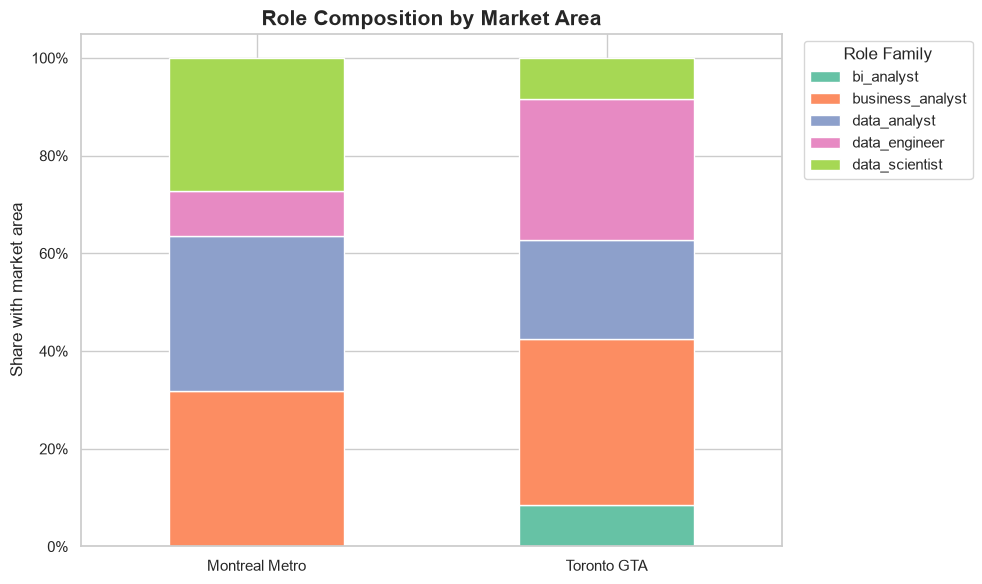

In [17]:
# Draw the role composition stacked bar chart for Toronto and Montreal
ax = role_mix.plot(kind='bar',
              stacked=True,
              figsize=(10, 6),
              color=sns.color_palette('Set2'),
              )
ax.set_title('Role Composition by Market Area', fontsize=15, fontweight='bold')
ax.set_xlabel('')
ax.set_ylabel('Share with market area')
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.tick_params(axis='x', rotation=0)
ax.legend(title='Role Family', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.savefig(
    output_directory / 'role_composition_by_market_area_Sept.png',
    dpi=200,
    bbox_inches='tight',
)
plt.show()

Findings

* Business analyst postings accounted for approximately one-third of the collected postings in both markets.
* Toronto had a substantially higher share of data engineer postings than Montréal, at approximately 28% compared with 9%.
* Montréal had higher relative shares of both data analyst and data scientist postings.
* All five role families appeared in the Toronto sample, while no BI analyst postings were observed in the smaller Montréal sample.
* These counts describe the collected sample, not the complete Toronto and Montreal labour markets.

## Key Findings

1. Python and SQL were the most broadly demanded technical skills.
2. Technical requirements varied meaningfully across role families, particularly
   between analytics-oriented and engineering-oriented positions.
3. SQL frequently appeared alongside Python, Power BI, Excel, and Tableau,
   indicating the importance of combined analytical toolsets.
4. Employers accepted a broad range of computing, engineering, quantitative,
   and business-related majors.
5. Soft skills were commonly mentioned but showed less role-specific variation.
6. Numeric experience requirements had limited coverage and were therefore
   treated as supplementary evidence.

## Limitations

- The dataset contains approximately 180 postings collected through one API.
- Some role families have relatively small sample sizes.
- Skill and education features were extracted using keyword-based rules.
- Missing extracted values do not necessarily indicate that employers had no requirement.
- The findings describe the current collection period and should not be interpreted
  as the entire Canadian job market.
